# Analyze mediation models

This notebook reads the results generated by `1_run_mediation_analyses.R`. It performs no model fitting.

In [1]:
"""
Name: Joshua Ashkinaze

Date: 2026-09-17

Description: Formats, reports, and visualizes the mediation analyses fit in R. The serial
model, in which closeness predicts transportation, is the primary specification; the parallel
model, with closeness and transportation's residuals left free to covary, is reported alongside
it as the alternative (SI: Mediation Model Selection). Freeing that covariance saturates the
parallel model exactly like the serial one, so the two cannot be distinguished by AIC or BIC;
this notebook does not attempt that comparison.

Inputs:
- study_comparison/tables/mediation_*.csv

Outputs:
- study_comparison/tables/tab_mediation_*.tex
- study_comparison/plots/mediation_paths.pdf, mediation_paths_grid.pdf: parallel model
- study_comparison/plots/mediation_paths_serial.pdf, mediation_paths_grid_serial.pdf: serial model
"""

import sys
from pathlib import Path

import numpy as np
import pandas as pd


STUDY_TOGGLES = {
    "pooled": "Control=='Pooled'",
    "placebo": "Control='Placebo'",
    "vignette": "Control='Vignette'"

}

def filter_for_control(tdf, control_type):
    """Filters for the proper control type"""
    return tdf[tdf['Control']==control_type]


def effects_table(model_name, effect_labels, tex_name, caption, tex_label):
    """Every study-by-control cell's defined effects for one model, displayed and saved as a
    LaTeX longtable."""
    rows = estimates[estimates.model.eq(model_name) & estimates.label.isin(effect_labels)].copy()
    rows['Effect'] = rows.label.map(effect_labels)
    rows['Estimate [95\\% CI]'] = rows.apply(
        lambda row: f"{row.est:+.3f} [{row['ci.lower']:+.3f}, {row['ci.upper']:+.3f}]", axis=1)
    display_table = rows[['study', 'control', 'Effect', 'Estimate [95\\% CI]']].rename(
        columns={'study': 'Study', 'control': 'Control'})
    display(display_table)
    display_table.to_latex(TABLE_DIR / tex_name, index=False, escape=False, longtable=True,
                           caption=caption, label=tex_label)
    return display_table

HERE = Path.cwd()
ROOT = next(path for path in [HERE, *HERE.parents] if (path / 'src' / 'helpers.py').exists())
TABLE_DIR = ROOT / 'study_comparison' / 'tables'
PLOT_DIR = ROOT / 'study_comparison' / 'plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'study_comparison'))

direction = pd.read_csv(TABLE_DIR / 'mediation_direction_tests.csv')
partial = pd.read_csv(TABLE_DIR / 'mediator_partial_correlations.csv')
estimates = pd.read_csv(TABLE_DIR / 'mediation_model_estimates.csv')
samples = pd.read_csv(TABLE_DIR / 'mediation_samples.csv')

PARALLEL_NAME = 'Multiple parallel'
SERIAL_NAME = 'Multiple serial: closeness -> transportation'


## 1. Which direction do the data tolerate?

In [2]:
CONTROL_TYPE = "Vignette"

def estimate_ci(row, prefix):
    return f"{row[f'{prefix}_b']:+.2f} [{row[f'{prefix}_ci_lower']:+.2f}, {row[f'{prefix}_ci_upper']:+.2f}]"

direction_display = pd.DataFrame({
    'Study': direction.study,
    'Control': direction.control,
    'Proposed chain': direction.direction.str.replace('->', r'$\rightarrow$', regex=False),
    '$n$': direction.n,
    'Unadjusted treatment coefficient': direction.apply(estimate_ci, axis=1, prefix='unadjusted'),
    'Adjusted treatment coefficient': direction.apply(estimate_ci, axis=1, prefix='adjusted'),
    'Tolerated': direction.tolerated.map({True: 'Yes', False: 'No'}),
})

direction_display = filter_for_control(direction_display, CONTROL_TYPE)
display(direction_display)

direction_display.to_latex(
    TABLE_DIR / 'tab_mediation_direction_tests.tex', index=False, escape=False, longtable=True,
    caption='Treatment coefficients before and after adjusting for the proposed upstream mediator. Coefficients are in SD units with 95\% HC1 confidence intervals.',
    label='tab:mediation_direction_tests')


<>:21: SyntaxWarning: invalid escape sequence '\%'
<>:21: SyntaxWarning: invalid escape sequence '\%'
/var/folders/4r/zf8yg_9n3qn26k_y7w56_gqr0000gp/T/ipykernel_48018/1887083934.py:21: SyntaxWarning: invalid escape sequence '\%'
  caption='Treatment coefficients before and after adjusting for the proposed upstream mediator. Coefficients are in SD units with 95\% HC1 confidence intervals.',


,Study,Control,Proposed chain,$n$,Unadjusted treatment coefficient,Adjusted treatment coefficient,Tolerated
0,Pooled,Vignette,AIM $\rightarrow$ transportation $\rightarrow$...,1265,"+0.37 [+0.27, +0.46]","+0.26 [+0.18, +0.35]",No
1,Pooled,Vignette,AIM $\rightarrow$ closeness $\rightarrow$ tran...,1265,"+0.23 [+0.12, +0.35]","+0.01 [-0.09, +0.11]",Yes
6,Study 1,Vignette,AIM $\rightarrow$ transportation $\rightarrow$...,664,"+0.36 [+0.22, +0.49]","+0.31 [+0.20, +0.43]",No
7,Study 1,Vignette,AIM $\rightarrow$ closeness $\rightarrow$ tran...,664,"+0.10 [-0.05, +0.26]","-0.10 [-0.24, +0.04]",Yes
12,Study 2,Vignette,AIM $\rightarrow$ transportation $\rightarrow$...,601,"+0.38 [+0.24, +0.51]","+0.21 [+0.09, +0.32]",No
13,Study 2,Vignette,AIM $\rightarrow$ closeness $\rightarrow$ tran...,601,"+0.38 [+0.22, +0.54]","+0.13 [-0.01, +0.28]",Yes


## 2. Partial correlation check

In [3]:
CONTROL_TYPE = "Vignette"


partial_display = pd.DataFrame({
    'Study': partial.study, 'Control': partial.control, '$n$': partial.n,
    '$r$': partial.raw_r.map('{:+.3f}'.format),
    'Partial $r$ [95\% CI]': partial.apply(lambda row: f"{row.partial_r:+.3f} [{row.ci_lower:+.2f}, {row.ci_upper:+.2f}]", axis=1),
}).query("Control=='{}'".format(CONTROL_TYPE))



display(partial_display)
partial_display.to_latex(
    TABLE_DIR / 'tab_mediator_partial_correlations.tex', index=False, escape=False, longtable=True,
    caption='Correlation between closeness and transportation before and after partialling out treatment.',
    label='tab:mediator_partial_correlations')


<>:7: SyntaxWarning: invalid escape sequence '\%'
<>:7: SyntaxWarning: invalid escape sequence '\%'
/var/folders/4r/zf8yg_9n3qn26k_y7w56_gqr0000gp/T/ipykernel_48018/4225674908.py:7: SyntaxWarning: invalid escape sequence '\%'
  'Partial $r$ [95\% CI]': partial.apply(lambda row: f"{row.partial_r:+.3f} [{row.ci_lower:+.2f}, {row.ci_upper:+.2f}]", axis=1),


,Study,Control,$n$,$r$,Partial $r$ [95\% CI]
0,Pooled,Vignette,1265,+0.524,"+0.515 [+0.47, +0.55]"
3,Study 1,Vignette,664,+0.491,"+0.492 [+0.43, +0.55]"
6,Study 2,Vignette,601,+0.562,"+0.544 [+0.48, +0.60]"


## 3. Both models fit identically

The parallel model frees closeness and transportation's residual covariance rather than fixing
it at zero, so it spends its last free parameter there instead of on the serial model's
closeness-to-transportation path. Both therefore fit exactly as many parameters as there are
observed moments in every cell: `1_run_mediation_analyses.R` checks this at fit time and halts if
it ever fails. Two saturated models reproduce the same observed covariance matrix exactly, so
their log-likelihood, AIC and BIC are identical by construction. We do not report a model
comparison; there is nothing for one to show.

In [4]:
###############
# Both models fit identically
###############

# a cheap parity check, not the proof itself: the R script's own df == 0 assertion is what
# guarantees saturation. This just confirms both models spend the same number of parameters.
free_parameters = (estimates[estimates.op.isin(['~', '~~'])]
                   .groupby(['study', 'control', 'model']).size().unstack('model'))
assert (free_parameters[PARALLEL_NAME] == free_parameters[SERIAL_NAME]).all(), \
    "parameter counts differ between the two models in at least one cell"
print("Free regression and covariance parameters per model, by cell (matching, as expected):")
display(free_parameters)

Free regression and covariance parameters per model, by cell (matching, as expected):


model             Multiple parallel  \
study   control                       
Pooled  Placebo                  15   
        Pooled                   15   
        Vignette                 15   
Study 1 Placebo                  10   
        Pooled                   10   
        Vignette                 10   
Study 2 Placebo                  10   
        Pooled                   10   
        Vignette                 10   

model             Multiple serial: closeness -> transportation  
study   control                                                 
Pooled  Placebo                                             15  
        Pooled                                              15  
        Vignette                                            15  
Study 1 Placebo                                             10  
        Pooled                                              10  
        Vignette                                            10  
Study 2 Placebo                                             10  
        Pooled                                              10  
        Vignette                                            10

## 4. Parallel effects and figures (alternative)

The parallel model is the alternative specification: closeness and transportation may each mediate
AIM's effect on their own, with their residual covariance left free rather than fixed at zero.

**Outputs:** `tables/tab_parallel_effects.tex`, `plots/mediation_paths.pdf`,
`plots/mediation_paths_grid.pdf`

,Study,Control,Effect,Estimate [95\% CI]
20,Pooled,Vignette,Via closeness,"+0.153 [+0.106, +0.210]"
21,Pooled,Vignette,Via transportation,"+0.050 [+0.024, +0.082]"
22,Pooled,Vignette,Total indirect,"+0.202 [+0.141, +0.267]"
23,Pooled,Vignette,Total,"+0.342 [+0.227, +0.457]"
24,Pooled,Vignette,Direct,"+0.140 [+0.039, +0.240]"
74,Pooled,Placebo,Via closeness,"+0.380 [+0.316, +0.449]"
75,Pooled,Placebo,Via transportation,"+0.019 [+0.001, +0.041]"
76,Pooled,Placebo,Total indirect,"+0.399 [+0.328, +0.477]"
77,Pooled,Placebo,Total,"+0.363 [+0.253, +0.465]"
78,Pooled,Placebo,Direct,"-0.036 [-0.151, +0.058]"


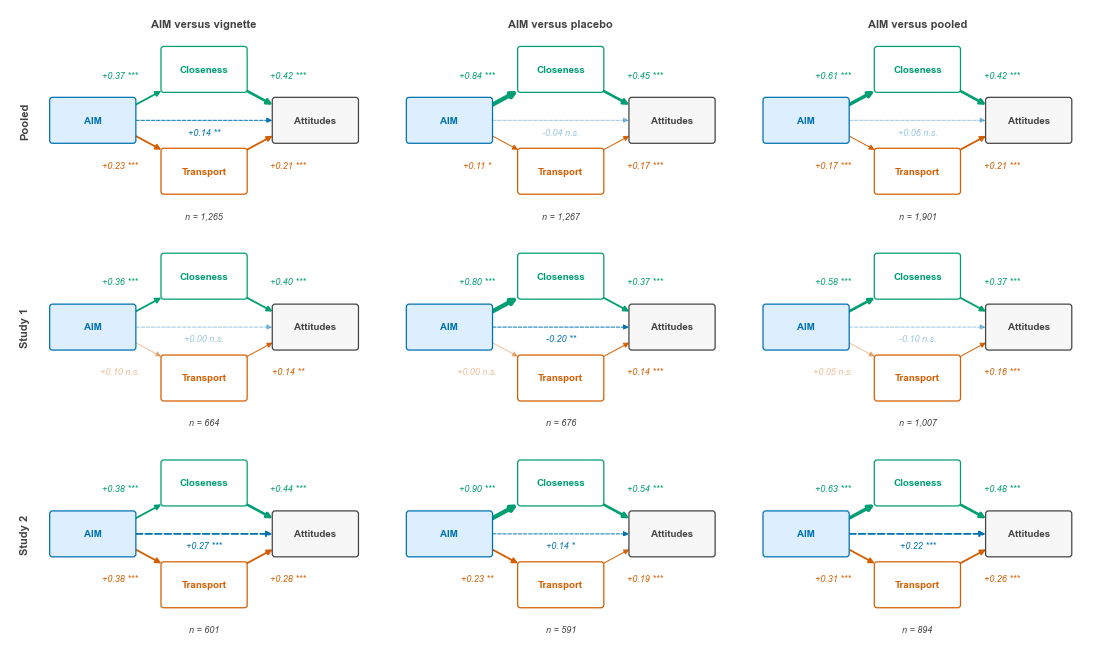

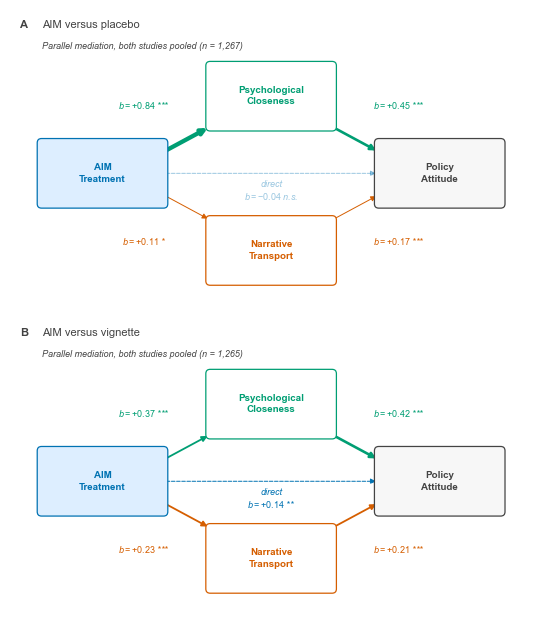

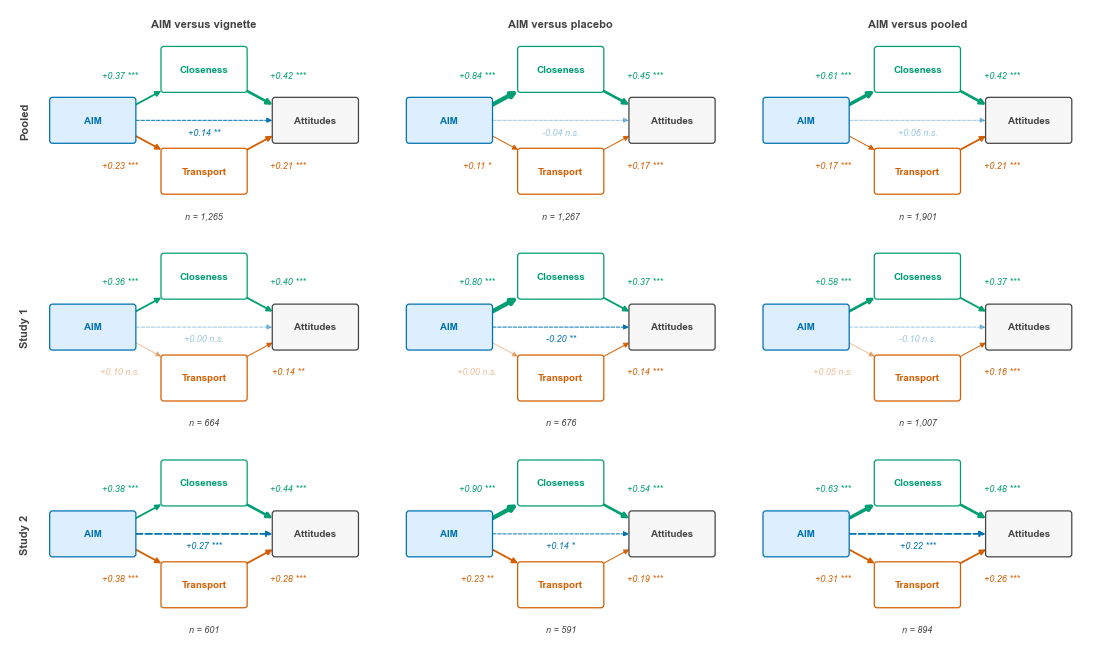

In [5]:
###############
# Parallel effects and figures (alternative)
###############

PARALLEL_EFFECT_LABELS = {
    'indirect_closeness': 'Via closeness', 'indirect_transport': 'Via transportation',
    'total_indirect': 'Total indirect', 'direct': 'Direct', 'total': 'Total',
}
effects_table(
    PARALLEL_NAME, PARALLEL_EFFECT_LABELS, 'tab_parallel_effects.tex',
    'Parallel multiple-mediator effects, with residual covariance free rather than fixed at '
    'zero, with 95\\% bias-corrected bootstrap intervals.', 'tab:parallel_effects')

import plot_mediation_paths

parallel_pooled = plot_mediation_paths.figure(model='parallel')
parallel_pooled.savefig(PLOT_DIR / 'mediation_paths.pdf', bbox_inches='tight')
parallel_grid = plot_mediation_paths.grid_figure(model='parallel')
parallel_grid.savefig(PLOT_DIR / 'mediation_paths_grid.pdf', bbox_inches='tight')
parallel_grid

## 5. Serial effects and figures (primary)

The serial model, the primary specification, routes closeness into transportation. Prior work and
Section 1's direction tests motivate that ordering, but because the two mediators were measured
concurrently, we present it as a descriptive decomposition rather than as evidence the mediators
operate sequentially (SI: Mediation Model Selection).

**Outputs:** `tables/tab_serial_effects.tex`, `plots/mediation_paths_serial.pdf`,
`plots/mediation_paths_grid_serial.pdf`

,Study,Control,Effect,Estimate [95\% CI]
45,Pooled,Vignette,Via closeness,"+0.153 [+0.106, +0.210]"
46,Pooled,Vignette,Via transportation,"+0.002 [-0.019, +0.026]"
47,Pooled,Vignette,Via closeness $\rightarrow$ transportation,"+0.047 [+0.030, +0.068]"
51,Pooled,Vignette,Total indirect,"+0.202 [+0.141, +0.267]"
52,Pooled,Vignette,Total,"+0.342 [+0.227, +0.457]"
53,Pooled,Vignette,Direct,"+0.140 [+0.039, +0.240]"
99,Pooled,Placebo,Via closeness,"+0.380 [+0.316, +0.449]"
100,Pooled,Placebo,Via transportation,"-0.026 [-0.047, -0.006]"
101,Pooled,Placebo,Via closeness $\rightarrow$ transportation,"+0.045 [+0.030, +0.064]"
105,Pooled,Placebo,Total indirect,"+0.399 [+0.328, +0.477]"


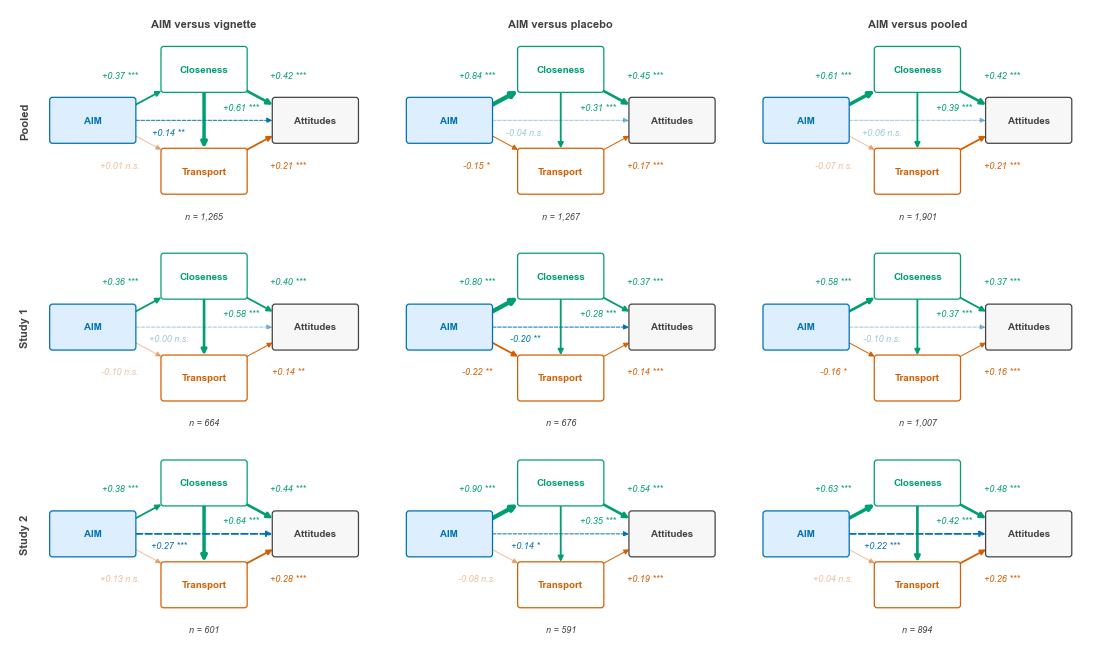

In [6]:
###############
# Serial effects and figures (primary)
###############

SERIAL_EFFECT_LABELS = {
    'indirect_closeness': 'Via closeness', 'indirect_transport': 'Via transportation',
    'indirect_serial': r'Via closeness $\rightarrow$ transportation',
    'total_indirect': 'Total indirect', 'direct': 'Direct', 'total': 'Total',
}
effects_table(
    SERIAL_NAME, SERIAL_EFFECT_LABELS, 'tab_serial_effects.tex',
    'Serial multiple-mediator effects with 95\\% bias-corrected bootstrap intervals.',
    'tab:serial_effects')

serial_pooled = plot_mediation_paths.figure(model='serial')
serial_pooled.savefig(PLOT_DIR / 'mediation_paths_serial.pdf', bbox_inches='tight')
serial_grid = plot_mediation_paths.grid_figure(model='serial')
serial_grid.savefig(PLOT_DIR / 'mediation_paths_grid_serial.pdf', bbox_inches='tight')
serial_grid